# Préprocessing des données SNCF

**Objectif :** Préparer les données de régularité des liaisons TGV pour leur analyse.

## 1. Chargement des librairies et des donnés

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
# Chargement des données brutes
df = pd.read_csv(
    "../data/raw/regularite-mensuelle-tgv-aqst.csv",
    sep=";"
)

print("Dimensions :", df.shape)
display(df.head())

# Création d'une copie de travail
df_clean = df.copy()

Dimensions : (12907, 26)


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


## 2. Diagnostic et traitement des anomalies

## 2.1. Traitement des observations incohérentes

In [7]:
# Calcul du nombre de trains ayant effectivement circulé
df_clean["Trains circulés"] = (
    df_clean["Nombre de circulations prévues"]
    - df_clean["Nombre de trains annulés"]
)

display(df_clean["Trains circulés"].describe())

count    12907.000000
mean       265.169985
std        181.363943
min        -21.000000
25%        145.000000
50%        224.000000
75%        348.000000
max       1099.000000
Name: Trains circulés, dtype: float64

In [6]:
# Identification des observations avec des effectifs incohérents
anomalies = (
    (df_clean["Trains circulés"] <= 0)
    | (df_clean["Nombre de trains en retard à l'arrivée"] < 0)
    | (
        df_clean["Nombre de trains en retard à l'arrivée"]
        > df_clean["Trains circulés"]
    )
)

print("Observations concernées :", anomalies.sum())
print("Part des observations (%) :", round(anomalies.mean() * 100, 2))

Observations concernées : 73
Part des observations (%) : 0.57


In [8]:
# Exclusion des observations présentant des effectifs incohérents
df_clean = df_clean.loc[~anomalies].copy()

print("Observations initiales :", len(df))
print("Observations conservées :", len(df_clean))
print("Observations exclues :", len(df) - len(df_clean))

Observations initiales : 12907
Observations conservées : 12834
Observations exclues : 73


In [9]:
# Vérification de la cohérence des effectifs après nettoyage
print("Circulations non positives :", (df_clean["Trains circulés"] <= 0).sum())

print("Retards à l'arrivée négatifs :",
      (df_clean["Nombre de trains en retard à l'arrivée"] < 0).sum())

print("Retards supérieurs aux circulations :",
      (df_clean["Nombre de trains en retard à l'arrivée"] > df_clean["Trains circulés"]).sum())

Circulations non positives : 0
Retards à l'arrivée négatifs : 0
Retards supérieurs aux circulations : 0


Le contrôle des effectifs a permis d'identifier 73 observations non exploitables, représentant 0,57 % des données initiales. Ces observations ont été exclues de la base de travail afin de garantir la cohérence du calcul des taux de retard à l'arrivée. Le fichier source a été conservé sans modification.

## 2.2. Traitement des valeurs négatives dans les retards

In [10]:
# Identification des valeurs négatives dans les seuils de retard
colonnes_retard = [
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min"
]

print((df_clean[colonnes_retard] < 0).sum())

Nombre trains en retard > 15min     0
Nombre trains en retard > 30min    43
Nombre trains en retard > 60min     0
dtype: int64


In [11]:
# Examen des observations présentant des retards négatifs
retards_negatifs = (df_clean[colonnes_retard] < 0).any(axis=1)

print("Observations concernées :", retards_negatifs.sum())

display(
    df_clean.loc[
        retards_negatifs,
        ["Date", "Gare de départ", "Gare d'arrivée"] + colonnes_retard
    ]
)

Observations concernées : 43


,Date,Gare de départ,Gare d'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
10326,2025-01,LAUSANNE,PARIS LYON,15,-4,9
10329,2025-01,DIJON VILLE,PARIS LYON,47,-1,30
10330,2025-01,DOUAI,PARIS NORD,21,-1,9
10357,2025-01,LE MANS,PARIS MONTPARNASSE,51,-1,30
10358,2025-01,MARSEILLE ST CHARLES,MARNE LA VALLEE,43,-2,17
10379,2025-01,LILLE,PARIS NORD,49,-1,18
10380,2025-01,LYON PART DIEU,LILLE,64,-44,21
10381,2025-01,LYON PART DIEU,MARNE LA VALLEE,42,-2,18
10382,2025-01,LYON PART DIEU,PARIS LYON,43,-3,17
10392,2025-01,QUIMPER,PARIS MONTPARNASSE,31,-1,14


Après le premier nettoyage, **43 observations présentent encore des valeurs négatives** dans la variable « Nombre trains en retard > 30min ». Ces anomalies sont concentrées entre janvier et mars 2025, avec des valeurs allant jusqu'à −44. En revanche, aucune valeur négative n'a été détectée pour les retards de plus de 15 et 60 minutes. Ces incohérences semblent donc spécifiques à la variable des retards de plus de 30 minutes et nécessitent un traitement particulier avant son utilisation dans les analyses.

In [12]:
# Traitement des valeurs négatives du nombre de retards supérieurs à 30 minutes
colonne = "Nombre trains en retard > 30min"

df_clean.loc[df_clean[colonne] < 0, colonne] = float("nan")

In [13]:
# Contrôle des valeurs négatives et manquantes après traitement
print("Valeurs négatives :", (df_clean[colonne] < 0).sum())
print("Valeurs manquantes :", df_clean[colonne].isna().sum())
print("Observations conservées :", len(df_clean))

Valeurs négatives : 0
Valeurs manquantes : 43
Observations conservées : 12834


Nous avons choisi de conserver les 43 observations présentant des valeurs négatives dans la variable « Nombre trains en retard > 30min », car les autres informations de ces lignes restent potentiellement exploitables. Supprimer ces observations entraînerait une perte inutile de données. Nous avons donc décidé de remplacer uniquement les valeurs incohérentes par `NaN`, afin de préserver les informations utiles tout en évitant de fausser les analyses.

## 2.3. Vérification de la cohérence des seuils de retard

In [14]:
# Vérification de la cohérence entre les seuils de retard
retard_15 = df_clean["Nombre trains en retard > 15min"]
retard_30 = df_clean["Nombre trains en retard > 30min"]
retard_60 = df_clean["Nombre trains en retard > 60min"]

print("Retards > 30 min supérieurs aux retards > 15 min :",
      (retard_30 > retard_15).sum())

print("Retards > 60 min supérieurs aux retards > 30 min :",
      (retard_60 > retard_30).sum())

print("Retards > 15 min supérieurs au total des retards :",
      (retard_15 > df_clean["Nombre de trains en retard à l'arrivée"]).sum())

Retards > 30 min supérieurs aux retards > 15 min : 3
Retards > 60 min supérieurs aux retards > 30 min : 311
Retards > 15 min supérieurs au total des retards : 31


In [15]:
# Identification des observations présentant des seuils incohérents
incoherences_seuils = (
    (retard_30 > retard_15)
    | (retard_60 > retard_30)
    | (retard_15 > df_clean["Nombre de trains en retard à l'arrivée"])
)

print("Observations concernées :", incoherences_seuils.sum())

display(
    df_clean.loc[
        incoherences_seuils,
        [
            "Date",
            "Gare de départ",
            "Gare d'arrivée",
            "Nombre de trains en retard à l'arrivée",
            "Nombre trains en retard > 15min",
            "Nombre trains en retard > 30min",
            "Nombre trains en retard > 60min"
        ]
    ].head(15)
)

Observations concernées : 345


,Date,Gare de départ,Gare d'arrivée,Nombre de trains en retard à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
15,2018-01,GRENOBLE,PARIS LYON,23,25,13.0,6
70,2018-01,LAUSANNE,PARIS LYON,21,22,9.0,2
160,2018-02,PARIS EST,NANCY,38,44,16.0,4
201,2018-02,GRENOBLE,PARIS LYON,35,41,18.0,2
301,2018-03,PARIS LYON,GRENOBLE,37,38,21.0,5
356,2018-03,GRENOBLE,PARIS LYON,31,32,9.0,3
2112,2019-05,PARIS LYON,BARCELONA,7,12,7.0,2
2174,2019-05,BARCELONA,PARIS LYON,7,13,5.0,3
2936,2019-12,PARIS LYON,LAUSANNE,12,13,5.0,2
2945,2019-12,PARIS LYON,AIX EN PROVENCE TGV,11,13,8.0,2


Le contrôle des seuils de retard révèle 345 observations présentant des incohérences. Parmi celles-ci, 311 présentent un nombre de retards supérieurs à 60 minutes plus élevé que celui des retards supérieurs à 30 minutes. On relève également 31 cas où les retards de plus de 15 minutes dépassent le nombre total de trains en retard à l'arrivée, ainsi que 3 cas où les retards de plus de 30 minutes dépassent ceux de plus de 15 minutes. Ces résultats nécessitent une vérification supplémentaire avant de définir les règles de nettoyage.

In [16]:
# Répartition annuelle des incohérences entre les seuils de retard
repartition = (
    df_clean.loc[incoherences_seuils, "Date"]
    .str[:4]
    .value_counts()
    .sort_index()
)

display(repartition.to_frame("Nombre d'observations"))

,Nombre d'observations
Date,
2018,6
2019,7
2020,20
2025,312


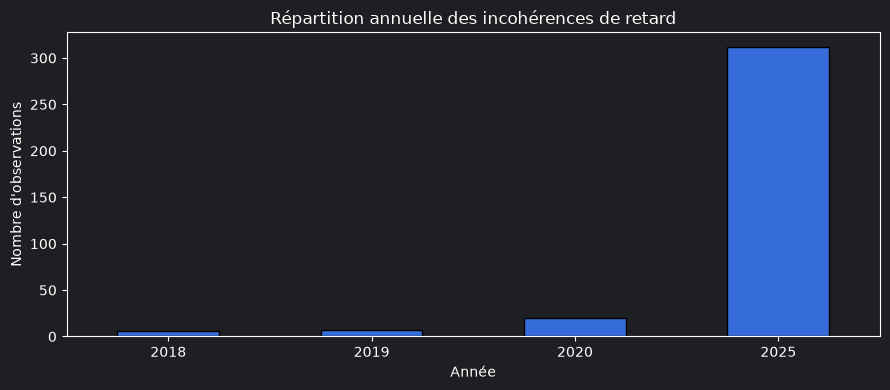

In [17]:
# Visualisation de la répartition annuelle des incohérences
repartition.plot(
    kind="bar",
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Répartition annuelle des incohérences de retard")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

L'analyse temporelle révèle que les incohérences entre les seuils de retard sont principalement concentrées en 2025, avec 312 observations sur 345, soit environ 90,4 %. Les autres anomalies sont réparties entre 2018, 2019 et 2020. Cette forte concentration en 2025 suggère un problème particulier dans les données de cette année. Nous conserverons les observations exploitables pour l'analyse globale des retards, mais les variables présentant des incohérences devront être traitées séparément avant leur utilisation.

## 2.4. Traitement des incohérences entre seuils

In [19]:
# Identification des incohérences entre seuils fixes
r15 = df_clean["Nombre trains en retard > 15min"]
r30 = df_clean["Nombre trains en retard > 30min"]
r60 = df_clean["Nombre trains en retard > 60min"]

incoherence_15_30 = r30 > r15
incoherence_30_60 = r60 > r30

print("Incohérences entre 15 et 30 min :", incoherence_15_30.sum())
print("Incohérences entre 30 et 60 min :", incoherence_30_60.sum())

Incohérences entre 15 et 30 min : 3
Incohérences entre 30 et 60 min : 311


In [20]:
# Mise en valeurs manquantes des seuils contradictoires
df_clean.loc[incoherence_15_30, "Nombre trains en retard > 30min"] = float("nan")

# Nouveau contrôle après le premier traitement
incoherence_30_60 = (
    df_clean["Nombre trains en retard > 60min"]
    > df_clean["Nombre trains en retard > 30min"]
)

print("Incohérences restantes :", incoherence_30_60.sum())

Incohérences restantes : 311


In [21]:
# Mise en valeurs manquantes des seuils contradictoires
df_clean.loc[incoherence_15_30, "Nombre trains en retard > 30min"] = float("nan")

# Nouveau contrôle après le premier traitement
incoherence_30_60 = (
    df_clean["Nombre trains en retard > 60min"]
    > df_clean["Nombre trains en retard > 30min"]
)

print("Incohérences restantes :", incoherence_30_60.sum())

Incohérences restantes : 311


Le contrôle des seuils de retard révèle encore 311 incohérences entre les retards supérieurs à 30 et 60 minutes, principalement concentrées en 2025. Après le traitement des valeurs négatives et des trois premières contradictions, la variable des retards supérieurs à 30 minutes comporte désormais 46 valeurs manquantes. Ces résultats montrent qu'un traitement complémentaire est nécessaire, sans supprimer les observations dont les autres indicateurs restent exploitables.

## 3. Conversion et validation des dates

In [22]:
# Conversion des dates au format datetime
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%Y-%m",
    errors="coerce"
)

print("Dates invalides :", df_clean["Date"].isna().sum())
print("Date minimale :", df_clean["Date"].min())
print("Date maximale :", df_clean["Date"].max())

Dates invalides : 0
Date minimale : 2018-01-01 00:00:00
Date maximale : 2026-09-01 00:00:00


## 4. Vérification des variables numériques restantes

In [23]:
# Identification des valeurs négatives dans les variables numériques
colonnes_numeriques = df_clean.select_dtypes(include="number").columns

valeurs_negatives = (df_clean[colonnes_numeriques] < 0).sum()

display(valeurs_negatives[valeurs_negatives > 0].to_frame("Nombre"))

,Nombre
Retard moyen de tous les trains au départ,170
Retard moyen des trains en retard à l'arrivée,2
Retard moyen de tous les trains à l'arrivée,122
Retard moyen trains en retard > 15 (si liaison concurrencée par vol),8


## 5 — Contrôle des valeurs manquantes

In [24]:
# Vérification des valeurs manquantes après les premiers traitements
manquants = df_clean.isna().sum()

display(manquants[manquants > 0].to_frame("Nombre"))

,Nombre
Commentaire annulations,12834
Commentaire retards au départ,12834
Commentaire retards à l'arrivée,12136
Nombre trains en retard > 30min,46


Le contrôle des variables numériques révèle quelques retards moyens négatifs, notamment 170 observations pour le retard moyen de tous les trains au départ et 122 à l'arrivée. Ces valeurs peuvent correspondre à des trains arrivés ou partis en avance et ne sont donc pas nécessairement erronées. Les valeurs manquantes concernent principalement les colonnes de commentaires, ainsi que 46 observations pour les retards supérieurs à 30 minutes. Ces dernières nécessitent une attention particulière, contrairement aux commentaires qui ne sont pas indispensables à notre analyse.

## 6 - Comprehension et traitement des 311 incohérences restantes

In [25]:
# Répartition mensuelle des incohérences restantes
display(
    df_clean.loc[incoherence_30_60, "Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .to_frame("Nombre d'incohérences")
)

,Nombre d'incohérences
Date,
2025-01,100
2025-02,102
2025-03,109


In [26]:
# Examen des seuils contradictoires
display(
    df_clean.loc[
        incoherence_30_60,
        [
            "Date",
            "Nombre trains en retard > 15min",
            "Nombre trains en retard > 30min",
            "Nombre trains en retard > 60min"
        ]
    ].head(15)
)

,Date,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
10324,2025-01-01,27,0.0,18
10325,2025-01-01,19,0.0,13
10327,2025-01-01,18,0.0,10
10328,2025-01-01,28,0.0,10
10331,2025-01-01,22,0.0,8
10332,2025-01-01,27,0.0,12
10333,2025-01-01,18,0.0,10
10334,2025-01-01,73,0.0,42
10335,2025-01-01,59,0.0,31
10336,2025-01-01,41,0.0,13


In [27]:
# Traitement des incohérences entre les seuils de 30 et 60 minutes
colonne_30 = "Nombre trains en retard > 30min"

df_clean.loc[incoherence_30_60, colonne_30] = float("nan")

In [28]:
# Contrôle des valeurs manquantes et des incohérences restantes
r30 = df_clean["Nombre trains en retard > 30min"]
r60 = df_clean["Nombre trains en retard > 60min"]

print("Valeurs manquantes (> 30 min) :", r30.isna().sum())
print("Incohérences 60 min > 30 min :", (r60 > r30).sum())
print("Observations conservées :", len(df_clean))

Valeurs manquantes (> 30 min) : 357
Incohérences 60 min > 30 min : 0
Observations conservées : 12834


## 7. Validation finale des données

In [35]:
# Bilan du nettoyage des données
print("Observations initiales :", len(df))
print("Observations conservées :", len(df_clean))
print("Observations exclues :", len(df) - len(df_clean))

print("\nValeurs manquantes dans les retards > 30 min :",
      df_clean["Nombre trains en retard > 30min"].isna().sum())

print("Dates invalides :", df_clean["Date"].isna().sum())
print("Doublons :", df_clean.duplicated().sum())

Observations initiales : 12907
Observations conservées : 12834
Observations exclues : 73

Valeurs manquantes dans les retards > 30 min : 357
Dates invalides : 0
Doublons : 0


In [36]:
# Validation des effectifs de circulation et de retard
assert (df_clean["Trains circulés"] > 0).all()

assert (
    df_clean["Nombre de trains en retard à l'arrivée"]
    .between(0, df_clean["Trains circulés"])
).all()

assert (
    df_clean["Nombre de trains annulés"]
    .between(0, df_clean["Nombre de circulations prévues"])
).all()

print("Validation des effectifs réussie.")

Validation des effectifs réussie.


## 8. Sauvegarde de la base nettoyée

In [40]:
# Sauvegarde de la base nettoyée

dossier = Path("../data/processed")
dossier.mkdir(parents=True, exist_ok=True)

fichier = dossier / "sncf_clean.csv"

df_clean.to_csv(fichier, sep=";", index=False)

print("Fichier enregistré :", fichier.resolve())

Fichier enregistré : /home/emman/projets/RailInsight-SNCF/data/processed/sncf_clean.csv


In [41]:
# Vérification de la sauvegarde
df_verification = pd.read_csv(fichier, sep=";")

print("Dimensions :", df_verification.shape)
print("Valeurs manquantes (> 30 min) :",
      df_verification["Nombre trains en retard > 30min"].isna().sum())

display(df_verification.head())

Dimensions : (12834, 27)
Valeurs manquantes (> 30 min) : 357


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",Trains circulés
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,6.511118,44.0,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336,865
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,5.363539,9.0,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333,405
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,2.938053,6.0,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111,226
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,5.292211,18.0,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852,505
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,4.882372,10.0,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386,468


Le préprocessing des données SNCF a permis de préparer une base exploitable à partir des 12 907 observations initiales. Après l'exclusion de 73 observations présentant des effectifs incohérents, **12 834 observations et 27 variables** ont été conservées. Les valeurs négatives et contradictoires de la variable des retards supérieurs à 30 minutes ont été remplacées par des valeurs manquantes, soit 357 au total. Par ailleurs, aucune date invalide, aucun doublon ni aucune incohérence dans les principaux effectifs de circulation n'a été détecté après traitement. La base nettoyée a été sauvegardée dans `data/processed/sncf_clean.csv`, sans modification du fichier source. Elle servira aux prochaines étapes de création des indicateurs et d'analyse de fiabilité.